# Data Exploration - Project Milestone P1

### Imports

In [1]:
# General
import os

# data manipulation
import json
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
from visualization import plot_df_histogram, plot_df_two_class, plot_df_pairgrid

# Interactive Jupyter
from ipywidgets import interact, IntSlider
from IPython.display import display, Markdown, Image

In [ ]:
# Load the JSON file
file_path = "../../data/newyorker_caption_contest/contests.json"
with open(file_path, "r") as file:
    contests = json.load(file)

# Convert the JSON data into a DataFrame for easier manipulation
contests_df = pd.DataFrame(contests)

current_selected_id = None  # store current selected contest_id

# Function to display contest details for a given contest_id
def display_contest(contest_id):
    global current_selected_id
    current_selected_id = contest_id  # Store the selected id
    contest = contests_df[contests_df["contest_id"] == contest_id]
    if not contest.empty:
        contest_data = contest.iloc[0]
        display(Markdown(f"### Contest ID: {contest_data['contest_id']}"))
        display(Markdown(f"**Image Path:** {contest_data['image']}"))
        display(Markdown(f"**Data Path:** {contest_data['data']}"))
        if contest_data["metadata"]:
            metadata = contest_data["metadata"]
            display(Markdown(f"**Number of Captions:** {metadata.get('num_captions', 'N/A')}"))
            display(Markdown(f"**Number of Votes:** {metadata.get('num_votes', 'N/A')}"))
            display(Markdown(f"**Image Locations:** {', '.join(metadata.get('image_locations', []))}"))
            display(Markdown(f"**Image Descriptions:** {', '.join(metadata.get('image_descriptions', []))}"))
            display(Markdown(f"**Entities:** {', '.join(metadata.get('entities', []))}"))
        else:
            display(Markdown("**Metadata:** None"))
        
        # Display the image with a fixed width
        image_path = os.path.join(os.path.dirname(file_path), contest_data['image'])
        if os.path.exists(image_path):
            display(Image(filename=image_path, width=1))  # Set the width to 400 pixels
        else:
            display(Markdown("**Image not found at the specified path.**"))
    else:
        display(Markdown("**Contest not found.**"))

# Create an interactive slider for contest_id selection
interact(
    display_contest,
    contest_id=IntSlider(
        min=contests_df["contest_id"].min(),
        max=contests_df["contest_id"].max(),
        step=1,
        value=contests_df["contest_id"].min(),
        description="Contest ID"
    )
)

interactive(children=(IntSlider(value=510, description='Contest ID', max=895, min=510), Output()), _dom_classe…

<function __main__.display_contest(contest_id)>

Current selected 'contest_id' = 640


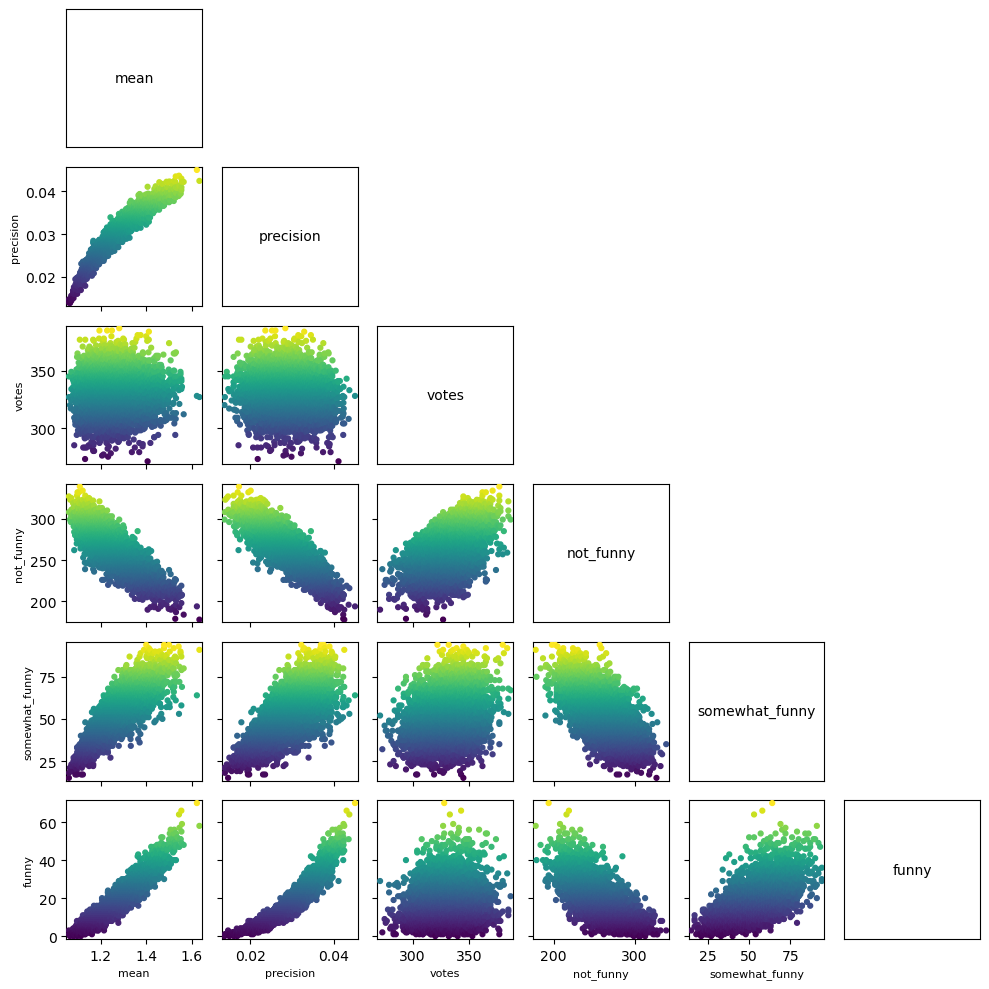

In [7]:
print("Current selected 'contest_id' =", current_selected_id)

# Load corresponding CSV file
if current_selected_id is not None:
    contest_row = contests_df[contests_df["contest_id"] == current_selected_id]
    if not contest_row.empty:
        csv_rel_path = contest_row.iloc[0]["data"]
        csv_path = os.path.join(os.path.dirname(file_path), csv_rel_path)
        if os.path.exists(csv_path):
            df_current = pd.read_csv(csv_path)
            plot_df_pairgrid(df_current, cols=["mean","precision","votes","not_funny", "somewhat_funny", "funny"], trace="none", cmap="viridis",
                 figsize=(10,10), include_upper=False, diagonal="name")
        else:
            print(f"CSV file not found at {csv_path}")
    else:
        print(f"No contest found for contest_id {current_selected_id}")
else:
    print("No contest_id selected.")
    

In [4]:
display(df_current.head(10))

,rank,caption,mean,precision,votes,not_funny,somewhat_funny,funny
0,0,I'm a congressman--obstruction is my job.,1.913043,0.094022,69,24,27,18
1,1,"I'm what they mean when they say, 'The middle ...",1.842105,0.191381,19,8,6,5
2,2,Does this suit make me look flat?,1.711111,0.112915,45,21,16,8
3,3,"When the right woman comes along, I'll know it.",1.625000,0.116657,32,15,14,3
4,4,"I used to lie in the gutter, but then I quit d...",1.617647,0.133610,34,19,9,6
5,5,"If you can meditate here, you can meditate any...",1.617647,0.126764,34,18,11,5
6,6,"Sorry for the inconvenience, I probably should...",1.593750,0.117598,32,16,13,3
7,7,I've decided to take it lying down.,1.593750,0.133647,32,18,9,5
8,8,Anyone who steps on me is out!,1.583333,0.259905,12,8,1,3
9,9,Guess I should have jumped from a few floors h...,1.566667,0.141286,30,18,7,5


In [5]:
# _ = plot_df_two_class(df_current, x_col="mean", y_col="precision", trace="None",
#                       figsize=(7, 5), title= None, cmap= 'viridis', save_path=None)

In [6]:
# _ = plot_df_two_class(df_current, x_col="mean", y_col="funny", trace="poly",
#                       figsize=(5, 5), title= None, cmap= 'viridis', save_path=None)
# _ = plot_df_two_class(df_current, x_col="mean", y_col="votes", trace="poly",
#                       figsize=(5, 5), title= None, cmap= 'viridis', save_path=None)